# 0 Importing relevant modules and csv dataset

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

df= pd.read_csv('Book_Sales.csv')
df

,Name,Author,User Rating,Reviews,Price,Year,Genre
0,10-Day Green Smoothie Cleanse,JJ Smith,4.7,17350,8,2016,Non Fiction
1,11/22/63: A Novel,Stephen King,4.6,2052,22,2011,Fiction
2,12 Rules for Life: An Antidote to Chaos,Jordan B. Peterson,4.7,18979,15,2018,Non Fiction
3,1984 (Signet Classics),George Orwell,4.7,21424,6,2017,Fiction
4,"5,000 Awesome Facts (About Everything!) (Natio...",National Geographic Kids,4.8,7665,12,2019,Non Fiction
...,...,...,...,...,...,...,...
545,Wrecking Ball (Diary of a Wimpy Kid Book 14),Jeff Kinney,4.9,9413,8,2019,Fiction
546,You Are a Badass: How to Stop Doubting Your Gr...,Jen Sincero,4.7,14331,8,2016,Non Fiction
547,You Are a Badass: How to Stop Doubting Your Gr...,Jen Sincero,4.7,14331,8,2017,Non Fiction
548,You Are a Badass: How to Stop Doubting Your Gr...,Jen Sincero,4.7,14331,8,2018,Non Fiction


# 1 Prepare the data



In [4]:
df.shape

(550, 7)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 550 entries, 0 to 549
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Name         550 non-null    object 
 1   Author       550 non-null    object 
 2   User Rating  550 non-null    float64
 3   Reviews      550 non-null    int64  
 4   Price        550 non-null    int64  
 5   Year         550 non-null    int64  
 6   Genre        550 non-null    object 
dtypes: float64(1), int64(3), object(3)
memory usage: 30.2+ KB


In [6]:
#There are no null values, so now I will look for duplicates in book name
name_df = df[df.duplicated(subset=['Name'])]
name_df = name_df.groupby('Name')['Name'].count()
name_df[name_df > 1]

,Name
Name,
Catching Fire (The Hunger Games),2
Crazy Love: Overwhelmed by a Relentless God,2
Dear Zoo: A Lift-the-Flap Book,3
First 100 Words,4
Game of Thrones Boxed Set: A Game of Thrones/A Clash of Kings/A Storm of Swords/A Feast for Crows,2
Giraffes Can't Dance,4
Gone Girl,2
Good to Great: Why Some Companies Make the Leap and Others Don't,3
Goodnight Moon,2


# 2 Make one justified cleaning decision

In [7]:
#There are many duplicate records, I will delete duplicate records as they can affect aggregation in analysis
df.drop_duplicates(subset=['Name'], inplace=True)
name_df = df[df.duplicated(subset=['Name'])]
name_df = name_df.groupby('Name')['Name'].count()
name_df[name_df > 1]
df

,Name,Author,User Rating,Reviews,Price,Year,Genre
0,10-Day Green Smoothie Cleanse,JJ Smith,4.7,17350,8,2016,Non Fiction
1,11/22/63: A Novel,Stephen King,4.6,2052,22,2011,Fiction
2,12 Rules for Life: An Antidote to Chaos,Jordan B. Peterson,4.7,18979,15,2018,Non Fiction
3,1984 (Signet Classics),George Orwell,4.7,21424,6,2017,Fiction
4,"5,000 Awesome Facts (About Everything!) (Natio...",National Geographic Kids,4.8,7665,12,2019,Non Fiction
...,...,...,...,...,...,...,...
538,Winter of the World: Book Two of the Century T...,Ken Follett,4.5,10760,15,2012,Fiction
539,Women Food and God: An Unexpected Path to Almo...,Geneen Roth,4.2,1302,11,2010,Non Fiction
540,Wonder,R. J. Palacio,4.8,21625,9,2013,Fiction
545,Wrecking Ball (Diary of a Wimpy Kid Book 14),Jeff Kinney,4.9,9413,8,2019,Fiction


# 3 Ask an analytical question

Is there a correlation between User Rating and number of Reviews?

# 4 Analyse before you plot

In [ ]:
# Let's look at mean, max and min for the user ratings and number of reviews
df['Reviews'].mean(), df['Reviews'].max(), df['Reviews'].min()

(np.float64(9799.68376068376), 87841, 37)

In [ ]:
df['User Rating'].mean(), df['User Rating'].max(), df['User Rating'].min()

(np.float64(4.608831908831909), 4.9, 3.3)

In [ ]:
df[df['Reviews'] == df['Reviews'].max()]

,Name,Author,User Rating,Reviews,Price,Year,Genre
534,Where the Crawdads Sing,Delia Owens,4.8,87841,15,2019,Fiction


In [ ]:
df[df['User Rating'] == df['User Rating'].max()]

,Name,Author,User Rating,Reviews,Price,Year,Genre
40,"Brown Bear, Brown Bear, What Do You See?",Bill Martin Jr.,4.9,14344,5,2017,Fiction
81,Dog Man and Cat Kid: From the Creator of Capta...,Dav Pilkey,4.9,5062,6,2018,Fiction
82,Dog Man: A Tale of Two Kitties: From the Creat...,Dav Pilkey,4.9,4786,8,2017,Fiction
83,Dog Man: Brawl of the Wild: From the Creator o...,Dav Pilkey,4.9,7235,4,2018,Fiction
85,Dog Man: Fetch-22: From the Creator of Captain...,Dav Pilkey,4.9,12619,8,2019,Fiction
86,Dog Man: For Whom the Ball Rolls: From the Cre...,Dav Pilkey,4.9,9089,8,2019,Fiction
87,Dog Man: Lord of the Fleas: From the Creator o...,Dav Pilkey,4.9,5470,6,2018,Fiction
146,"Goodnight, Goodnight Construction Site (Hardco...",Sherri Duskey Rinker,4.9,7038,7,2012,Fiction
151,Hamilton: The Revolution,Lin-Manuel Miranda,4.9,5867,54,2016,Non Fiction
153,Harry Potter and the Chamber of Secrets: The I...,J.K. Rowling,4.9,19622,30,2016,Fiction


In [ ]:
df[df['Reviews'] == df['Reviews'].min()]

,Name,Author,User Rating,Reviews,Price,Year,Genre
78,Divine Soul Mind Body Healing and Transmission...,Zhi Gang Sha,4.6,37,6,2009,Non Fiction


In [ ]:
df[df['User Rating'] == df['User Rating'].min()]

,Name,Author,User Rating,Reviews,Price,Year,Genre
353,The Casual Vacancy,J.K. Rowling,3.3,9372,12,2012,Fiction


# 5 Choose the visual deliberately

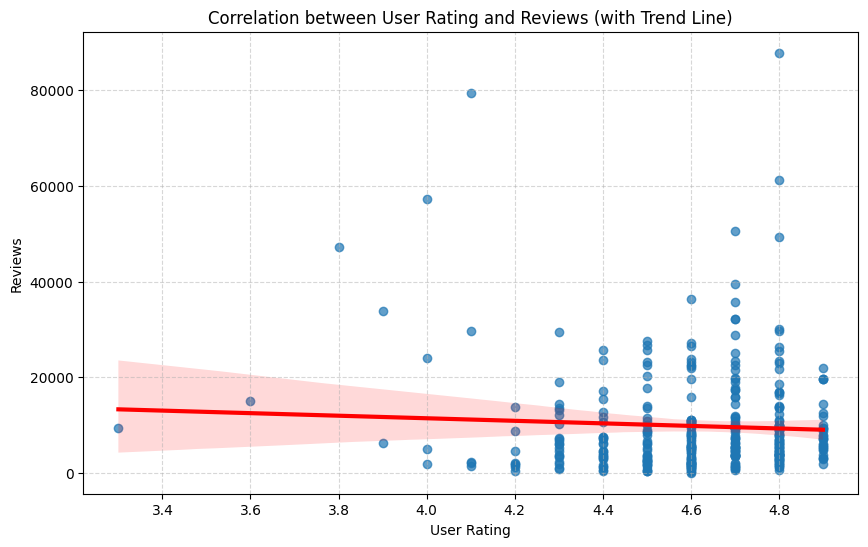

In [ ]:
plt.figure(figsize=(10,6))
sns.regplot(data=df, x='User Rating', y='Reviews', scatter_kws={'alpha':0.7}, line_kws={'color':'red', 'linewidth':3})
plt.title('Correlation between User Rating and Reviews (with Trend Line)')
plt.xlabel('User Rating')
plt.ylabel('Reviews')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

The scatter plot is used as it can show a correlation between two variables. There is no correlation as the lowest user ratings have very few points of data, while visualising the data is heavily skewed because of the density of lower review amounts.  However, due to the user ratings not being continuous, a bar chart can be used to look at the distribution of user ratings by review instead.

# 6 Challenge the visual

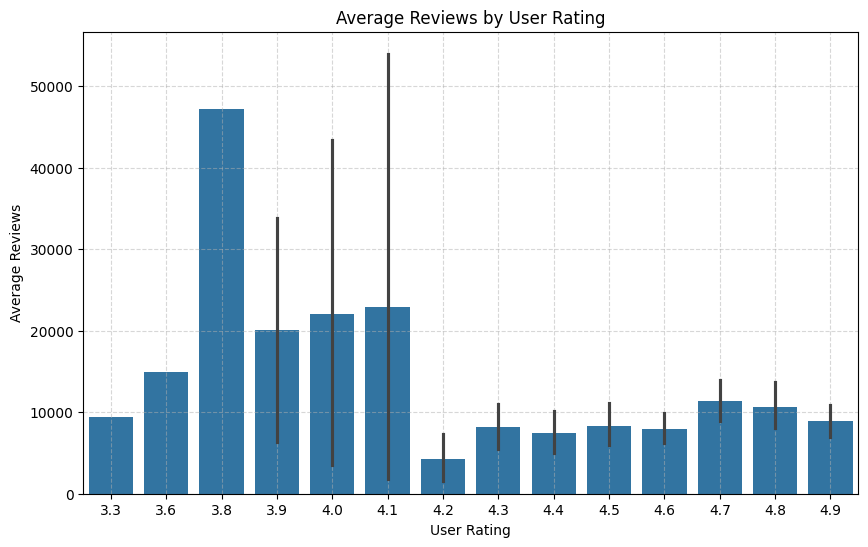

In [ ]:
#A bar chart to look at the distribution of the average of the reviews
plt.figure(figsize=(10,6))
sns.barplot(data=df, x='User Rating', y='Reviews', estimator=np.mean)
plt.title('Average Reviews by User Rating')
plt.xlabel('User Rating')
plt.ylabel('Average Reviews')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


The distribution shows that there is not a correlation between the user ratings and reviews and that the distribution is non-standard. There are many more reviews at 4.2 and up which reduces the error. Whilst on the scatter plot, the data from 4.2 onwards might look like a positive correlation, the overall trendline actually goes down, due to the density of lower number of reviews. The trend, however, might therefore be, the highest number of reviews is a positive correlation with user rating past 4.2.

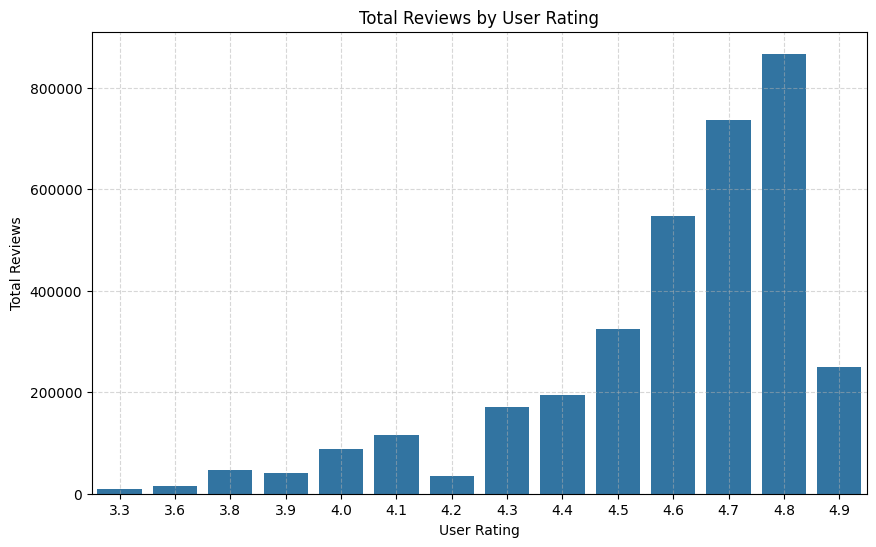

In [ ]:
# A bar chart now looking at total reviews by user rating
plt.figure(figsize=(10,6))
sns.barplot(data=df, x='User Rating', y='Reviews', estimator=sum, errorbar=None)
plt.title('Total Reviews by User Rating')
plt.xlabel('User Rating')
plt.ylabel('Total Reviews')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

Overall, I think this second chart is more useful as we can see a beginning of an exponential curve between total reviews and user rating. This suggests that better received books are not more likely to get reviewed, but that there are a lot more well received books.

# 7 Communicate the result

I investigated the relationship of number of reviews by user rating. There appears to be no correlation that can be gleaned. There does seem to be a relationship between total number of reviews by user rating, which suggests a lot more books in the better user rating ranges. I would suggest to look at which genres are received well by user rating, as there are more total reviews and customer noise for books in this range.